# Facial Emotion Recognition on RAF-DB with a Fine-Tuned EfficientNet-B2

**Author:** Yéo Mifolo Elisée ([@mifolotech](https://github.com/mifolotech))
**Context:** Machine Learning course project, B.Sc. Computer Systems and Software Engineering, Jesuit University of Abidjan (CERAP), Côte d'Ivoire

---

### Problem
Recognising a person's emotion from their face is useful in human–computer interaction, assistive technologies and affective computing. The task here is to classify a **real-world colour face image** (aligned, 100×100 pixels) into one of **7 emotions**: *Surprise, Fear, Disgust, Happy, Sad, Angry, Neutral*.

### Approach in one sentence
An **EfficientNet-B2** pre-trained on ImageNet is fine-tuned on RAF-DB, with strong data augmentation, random erasing, label smoothing, a class-balanced loss, dropout and stochastic depth, two learning rates with warm-up and cosine decay, an exponential moving average of the weights (EMA), early stopping and 2-view test-time augmentation.

### From the first version to this one
A first version (same backbone, plain cross-entropy, light augmentation) reached **84.08 % test accuracy** but **overfitted**: training accuracy reached 99.6 % while validation accuracy stayed around 82 %, and the validation loss increased after epoch 3. Every technique listed above targets this problem; Section 4 explains each one.

### Notebook structure
| Section | Content |
|---|---|
| 1. Setup | Libraries, random seeds, mixed precision, platform (Colab or Kaggle) |
| 2. Data | Dataset, train/validation/test split, preprocessing, class distribution, augmentation |
| 3. Model | Architecture |
| 4. Training | Loss function, training strategy, hyperparameters, automatic resume |
| 5. Evaluation | Accuracy, F1-score, learning curves, confusion matrix |
| 6. Error analysis | Most confused emotions, examples of correct and incorrect predictions |
| 7. Final results | Summary of the results, saved to `results.json` |

> **How to run:** open in **Google Colab** (*Runtime → Change runtime type → T4 GPU*) and place `RAFDB.zip` in the Drive folder defined in Section 1, or open in **Kaggle** with RAF-DB added as a private dataset (*+ Add Input*) and *GPU T4* enabled. Then *Run all*: the notebook detects the platform automatically.
> Training is saved after every epoch: if the session disconnects, simply run all cells again and training **resumes where it stopped**. Once training is finished, running the notebook again only loads the trained weights.

## 1. Setup

In [1]:
!pip install -q timm albumentations scikit-learn

In [2]:
import os, json, math, random, zipfile, time, importlib.util
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import timm
from timm.utils import ModelEmaV2
import albumentations as A
from albumentations.pytorch import ToTensorV2

from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score)

# Reproducibility: fixes the seeds of Python, NumPy and PyTorch
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Mixed precision: computations in float16 on the GPU (about 2x faster on a T4),
# while the weights stay in float32 for numerical stability
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"

print("PyTorch       :", torch.__version__)
print("timm          :", timm.__version__)
print("Albumentations:", A.__version__)
print("OpenCV        :", cv2.__version__)
print("scikit-learn  :", sklearn.__version__)
print("GPU           :", torch.cuda.get_device_name(0) if USE_AMP else "NONE - enable a GPU runtime!")

# Platform: Google Colab (Drive) or Kaggle
IN_COLAB  = importlib.util.find_spec("google.colab") is not None
ON_KAGGLE = (not IN_COLAB) and ("KAGGLE_KERNEL_RUN_TYPE" in os.environ or os.path.exists("/kaggle/working"))

if ON_KAGGLE:
    DATA_SOURCE = "/kaggle/input"                 # private RAF-DB dataset added with "+ Add Input"
    EXTRACT_DIR = "/kaggle/working/dataset_rafdb"
    RUN_DIR     = "/kaggle/working/outputs/"      # download from the "Output" panel
else:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_SOURCE = "/content/drive/MyDrive/Machine Learning/Emotion Recognition RAF DB/"
    EXTRACT_DIR = "/content/dataset_rafdb"
    RUN_DIR     = DATA_SOURCE + "outputs/"        # weights, history and results are saved here

FIG_DIR = RUN_DIR + "figures/"
os.makedirs(FIG_DIR, exist_ok=True)

WEIGHTS_PATH    = RUN_DIR + "best_model.pth"      # best epoch (highest validation accuracy)
CHECKPOINT_PATH = RUN_DIR + "checkpoint_last.pth" # automatic resume if the session disconnects
HISTORY_PATH    = RUN_DIR + "history.csv"
DONE_PATH       = RUN_DIR + "training.done"

print("Platform      :", "Kaggle" if ON_KAGGLE else "Google Colab", "| results ->", RUN_DIR)

PyTorch       : 2.11.0+cu130
timm          : 1.0.30
Albumentations: 2.0.8
OpenCV        : 4.14.0
scikit-learn  : 1.6.1
GPU           : Tesla T4
Mounted at /content/drive
Platform      : Google Colab | results -> /content/drive/MyDrive/Machine Learning/Emotion Recognition RAF DB/outputs/


## 2. Data

### Dataset
**RAF-DB** (*Real-world Affective Faces Database*, Li, Deng & Du, CVPR 2017) contains face images collected from the Internet, with large variations in age, gender, ethnicity, head pose, lighting and occlusion (glasses, hands, hair). Each image was labelled by about **40 annotators**. The **basic emotion** subset is used: 7 classes, about 12,000 training and 3,000 test images (official split), aligned and resized to 100×100 pixels.

Two properties of RAF-DB limit the accuracy any model can reach:
- **Ambiguous expressions**: real faces often mix several emotions (e.g. *Fear* and *Surprise*, *Disgust* and *Angry*), so even human annotators disagree on some images.
- **Class imbalance**: *Happy* represents almost 40 % of the images, *Fear* and *Disgust* only a few percent each.

**Licence:** RAF-DB is **not redistributed** with this project. Access must be requested from its authors (Pattern Recognition & Intelligent System Laboratory, Beijing University of Posts and Telecommunications) and is granted for non-commercial research use only. The original project page is no longer online; the contact address given in the paper is `whdeng@bupt.edu.cn`.
Reference: S. Li, W. Deng, J. Du, *Reliable Crowdsourcing and Deep Locality-Preserving Learning for Expression Recognition in the Wild*, CVPR 2017. [Paper](https://openaccess.thecvf.com/content_cvpr_2017/papers/Li_Reliable_Crowdsourcing_and_CVPR_2017_paper.pdf)

Expected structure: `train/1 … train/7` and `test/1 … test/7` (folder *k* = class *k*).

### Split
- **Train (90 %)** and **validation (10 %)** are taken from the `train/` folder with a stratified split (same class proportions).
- **Test**: the `test/` folder, used **only at the end** for the final evaluation, never to choose hyperparameters or the best epoch.

In [3]:
def find_split_dirs(base):
    # Returns the first folder containing both "train" and "test" sub-folders
    # (followlinks=True: Kaggle mounts input datasets as symbolic links)
    for root, dirs, _ in os.walk(base, followlinks=True):
        if "train" in dirs and "test" in dirs:
            return os.path.join(root, "train"), os.path.join(root, "test")
    return None, None

# 1) Dataset already extracted (previous run in this session, or Kaggle input)
train_dir, test_dir = find_split_dirs(EXTRACT_DIR) if os.path.exists(EXTRACT_DIR) else (None, None)
if train_dir is None and ON_KAGGLE:
    train_dir, test_dir = find_split_dirs(DATA_SOURCE)

# 2) Otherwise, extract RAFDB.zip (only the first time in a session)
if train_dir is None:
    zips = [os.path.join(r, f) for r, _, fs in os.walk(DATA_SOURCE, followlinks=True)
            for f in fs if f.lower() == "rafdb.zip"] if ON_KAGGLE else [DATA_SOURCE + "RAFDB.zip"]
    if not zips or not os.path.exists(zips[0]):
        raise FileNotFoundError("RAFDB.zip not found in " + DATA_SOURCE)
    print("Extracting", zips[0], "...")
    with zipfile.ZipFile(zips[0]) as z:
        z.extractall(EXTRACT_DIR)
    train_dir, test_dir = find_split_dirs(EXTRACT_DIR)

assert train_dir is not None, "RAF-DB not found: check the location of RAFDB.zip"
print("Train folder:", train_dir)
print("Test folder :", test_dir)

Extracting /content/drive/MyDrive/Machine Learning/Emotion Recognition RAF DB/RAFDB.zip ...
Train folder: /content/dataset_rafdb/RAFDB/train
Test folder : /content/dataset_rafdb/RAFDB/test


### Preprocessing
1. Images are read in **RGB** and resized to **224×224** (the input resolution EfficientNet works best with; the original 100×100 faces are enlarged).
2. **Normalisation** with the ImageNet mean and standard deviation, because the backbone was pre-trained on ImageNet.
3. Labels are integers from 0 to 6 (folder `1` → *Surprise*, …, folder `7` → *Neutral*).

In [4]:
CLASS_NAMES = ["Surprise", "Fear", "Disgust", "Happy", "Sad", "Angry", "Neutral"]
NUM_CLASSES = len(CLASS_NAMES)

def load_split(path):
    # Returns the image paths and labels of a folder; folders and files are sorted
    # so that the order, and therefore the split, is identical on every run
    paths, labels = [], []
    class_dirs = sorted([d for d in os.listdir(path) if os.path.isdir(os.path.join(path, d))], key=int)
    assert len(class_dirs) == NUM_CLASSES, f"Expected 7 class folders, found {class_dirs}"
    for label, name in enumerate(class_dirs):
        folder = os.path.join(path, name)
        for f in sorted(os.listdir(folder)):
            if f.lower().endswith((".png", ".jpg", ".jpeg")):
                paths.append(os.path.join(folder, f))
                labels.append(label)
    return paths, np.array(labels)

all_paths, y_all = load_split(train_dir)
test_paths, y_test = load_split(test_dir)

X_train, X_val, y_train, y_val = train_test_split(
    all_paths, y_all, test_size=0.1, stratify=y_all, random_state=SEED)

print("Train:", len(X_train), "| Validation:", len(X_val), "| Test:", len(test_paths))

Train: 11043 | Validation: 1228 | Test: 3065


### Class distribution
A model trained on imbalanced data tends to favour large classes. This is addressed in Section 4 with a class-balanced loss, and the **macro F1-score** (every class counts equally) is reported next to the accuracy.

          Train + validation  Test  Share (%)
Surprise                1290   326       10.5
Fear                     281    74        2.3
Disgust                  717   160        5.8
Happy                   4772  1185       38.9
Sad                     1982   478       16.2
Angry                    705   162        5.7
Neutral                 2524   680       20.6 



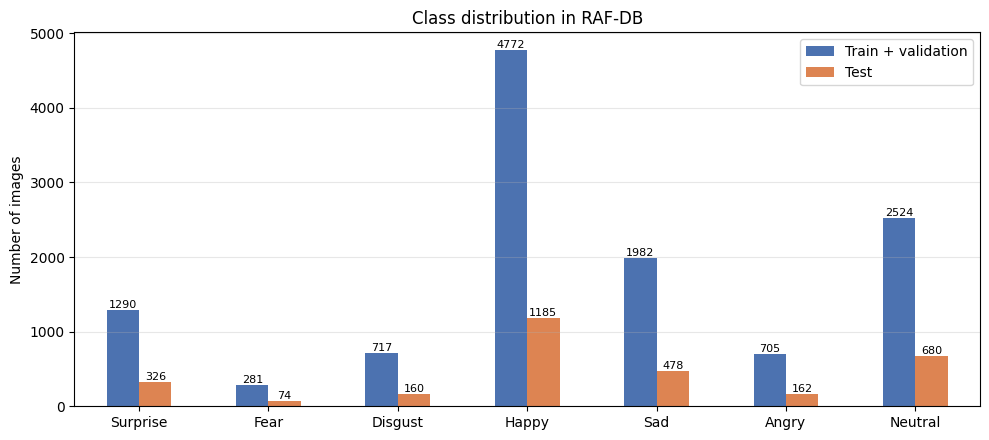

In [5]:
counts = pd.DataFrame({
    "Train + validation": np.bincount(y_all, minlength=NUM_CLASSES),
    "Test": np.bincount(y_test, minlength=NUM_CLASSES),
}, index=CLASS_NAMES)
counts["Share (%)"] = (100 * counts["Train + validation"] / counts["Train + validation"].sum()).round(1)
print(counts, "\n")

ax = counts[["Train + validation", "Test"]].plot.bar(figsize=(10, 4.5), rot=0, color=["#4C72B0", "#DD8452"])
ax.set_ylabel("Number of images")
ax.set_title("Class distribution in RAF-DB")
ax.grid(axis="y", alpha=0.3)
for container in ax.containers:
    ax.bar_label(container, fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR + "class_distribution.png", dpi=150)
plt.show()

### Data augmentation
Applied to **training images only**, differently at every epoch, so the model never sees exactly the same face twice:
- **random resized crop** (keeps 80–100 % of the face),
- **horizontal flip** (a mirrored face keeps the same emotion),
- small **affine** transformations (±5 % shift, ±10° rotation),
- **colour jitter** (brightness, contrast, saturation, hue) and occasional **grayscale**,
- **random erasing**: 1 to 3 black rectangles hide part of the face in half of the images. The model cannot rely on a single region (only the mouth, for example) and must use the whole face.

Validation and test images are only resized and normalised. Below: one training image and five random augmented versions.

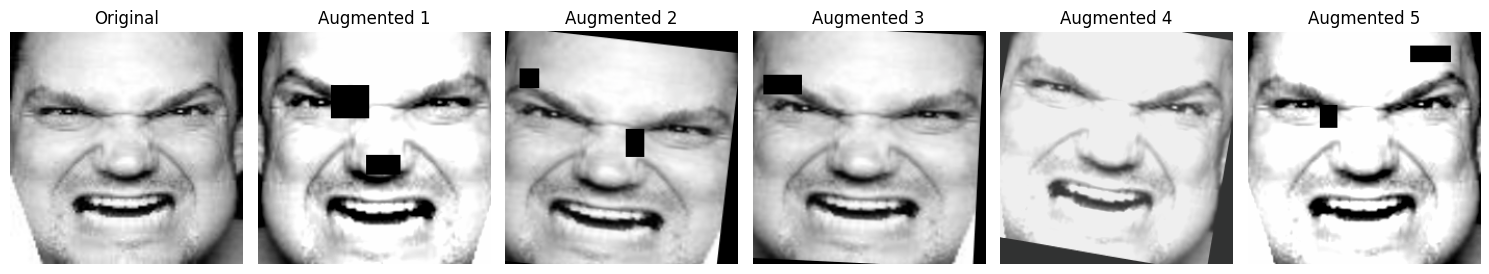

In [6]:
IMG_SIZE = 224
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

train_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.RandomResizedCrop(size=(IMG_SIZE, IMG_SIZE), scale=(0.8, 1.0), ratio=(0.9, 1.1), p=1.0),
    A.HorizontalFlip(p=0.5),
    A.Affine(translate_percent=(-0.05, 0.05), rotate=(-10, 10), p=0.5),
    A.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.05, p=0.6),
    A.ToGray(p=0.1),
    A.CoarseDropout(num_holes_range=(1, 3), hole_height_range=(16, 40),
                    hole_width_range=(16, 40), fill=0, p=0.5),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])

eval_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])

def read_rgb(path):
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Could not read image: {path}")
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def denormalize(t):
    return np.clip(t.permute(1, 2, 0).numpy() * np.array(STD) + np.array(MEAN), 0, 1)

fig, axes = plt.subplots(1, 6, figsize=(15, 3))
axes[0].imshow(cv2.resize(read_rgb(X_train[0]), (IMG_SIZE, IMG_SIZE)))
axes[0].set_title("Original")
for i in range(1, 6):
    axes[i].imshow(denormalize(train_transform(image=read_rgb(X_train[0]))["image"]))
    axes[i].set_title(f"Augmented {i}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR + "augmentation_examples.png", dpi=150)
plt.show()

In [7]:
class RAFDBDataset(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths, self.labels, self.transform = paths, labels, transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        image = self.transform(image=read_rgb(self.paths[i]))["image"]
        return image, torch.tensor(int(self.labels[i]), dtype=torch.long)

def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s)
    random.seed(s)

BATCH_SIZE = 64
g = torch.Generator()
g.manual_seed(SEED)
loader_args = dict(batch_size=BATCH_SIZE, num_workers=2, pin_memory=USE_AMP, worker_init_fn=seed_worker)

train_loader = DataLoader(RAFDBDataset(X_train, y_train, train_transform), shuffle=True,
                          drop_last=True, generator=g, **loader_args)
val_loader   = DataLoader(RAFDBDataset(X_val, y_val, eval_transform), shuffle=False, **loader_args)
test_loader  = DataLoader(RAFDBDataset(test_paths, y_test, eval_transform), shuffle=False, **loader_args)

## 3. Model

RAF-DB is small for training a deep network from scratch, so the model reuses **EfficientNet-B2 pre-trained on ImageNet** (*transfer learning*), loaded from the `timm` library.

```
Input 224×224×3 (RGB face)
 → EfficientNet-B2 backbone (ImageNet weights), stochastic depth 0.2
 → Global average pooling (1408 features)
 → Dropout 0.3
 → Linear 1408 → 7 (logits; softmax applied in the loss and at prediction time)
```

EfficientNet scales depth, width and resolution together, which gives a good accuracy for its size (about 7.7 million parameters, much smaller than ResNet50).

In [8]:
DROP_RATE, DROP_PATH_RATE = 0.3, 0.2

def build_model(pretrained=True):
    return timm.create_model("efficientnet_b2", pretrained=pretrained, num_classes=NUM_CLASSES,
                             drop_rate=DROP_RATE, drop_path_rate=DROP_PATH_RATE)

model = build_model().to(device)
print(f"Parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.1f} M")

Parameters: 7.7 M


## 4. Training

### Loss function
**Cross-entropy** with two additions:
- **Label smoothing (0.1)**: the target is 0.9 for the true class instead of 1.0. This keeps the model from becoming over-confident, which was the cause of the rising validation loss in the first version.
- **Class-balanced weights**: errors on rare classes cost more. Each class gets the weight $\sqrt{N / (K \cdot n_c)}$, where $n_c$ is its number of images, normalised so that the average weight is 1. The square root keeps the correction moderate, so that frequent classes are not sacrificed.

In [9]:
counts_train = np.bincount(y_train, minlength=NUM_CLASSES)
class_weights = np.sqrt(len(y_train) / (NUM_CLASSES * counts_train))
class_weights = class_weights / np.sum(class_weights * counts_train / len(y_train))  # average weight = 1
for name, w in zip(CLASS_NAMES, class_weights):
    print(f"{name:9}: {w:.2f}")

LABEL_SMOOTHING = 0.1
loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(class_weights, dtype=torch.float32, device=device),
                              label_smoothing=LABEL_SMOOTHING)

Surprise : 1.27
Fear     : 2.71
Disgust  : 1.70
Happy    : 0.66
Sad      : 1.02
Angry    : 1.71
Neutral  : 0.91


### Training strategy
- **Two learning rates**: the new classifier learns fast (1e-3) while the pre-trained backbone is only gently adjusted (2e-4), so the ImageNet features are not destroyed.
- **Warm-up + cosine schedule**: the learning rate rises linearly during the first 2 epochs, then decreases following a **cosine** curve down to 1 % of its maximum. Large steps at the beginning, small precise steps at the end.
- **AdamW** optimiser with weight decay 0.05 (a regularisation that keeps weights small).

Four techniques reduce overfitting, so that the training and validation curves stay close:
- **Data augmentation and random erasing** (Section 2).
- **Dropout and stochastic depth**: during training, random neurons and whole residual blocks are switched off, so the network cannot rely on any single path.
- **EMA (Exponential Moving Average) of the weights**: the model used for validation and for the final predictions is a running average of the weights over the last training steps. It is more stable than the weights of a single step, which gives a smoother validation curve and usually a better accuracy.
- **Early stopping**: training stops when the validation accuracy has not improved for 7 epochs.

### Hyperparameters
| Hyperparameter | Value |
|---|---|
| Input size | 224×224×3 |
| Batch size | 64 |
| Epochs | up to 30 (early stopping, patience 7 on validation accuracy) |
| Optimiser | AdamW, weight decay 0.05 |
| Learning rate | backbone 2e-4, classifier 1e-3 |
| Learning-rate schedule | 2 epochs linear warm-up, then cosine decay to 1 % |
| Label smoothing | 0.1 |
| Class-balanced loss | weights $\sqrt{N / (K \cdot n_c)}$ |
| Dropout / stochastic depth | 0.3 / 0.2 |
| Random erasing | probability 0.5, 1–3 rectangles of 16–40 px |
| EMA decay | 0.998 |
| Precision | mixed float16 |

The weights of the epoch with the **highest validation accuracy** are kept.

In [10]:
EPOCHS = 30
PATIENCE = 7
LR_BACKBONE, LR_HEAD = 2e-4, 1e-3
WEIGHT_DECAY = 0.05
LR_WARMUP_EPOCHS = 2
EMA_DECAY = 0.998

# Optimiser with two parameter groups: pre-trained backbone vs. new classifier
head_params = list(model.get_classifier().parameters())
head_ids = {id(p) for p in head_params}
optimizer = optim.AdamW([
    {"params": [p for p in model.parameters() if id(p) not in head_ids], "lr": LR_BACKBONE},
    {"params": head_params, "lr": LR_HEAD},
], weight_decay=WEIGHT_DECAY)

# Linear warm-up, then cosine decay down to 1 % (updated at every batch)
steps_per_epoch = len(train_loader)
total_steps, warmup_steps = EPOCHS * steps_per_epoch, LR_WARMUP_EPOCHS * steps_per_epoch

def lr_factor(step):
    if step < warmup_steps:
        return (step + 1) / warmup_steps
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * progress))

scheduler = optim.lr_scheduler.LambdaLR(optimizer, lr_factor)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
ema = ModelEmaV2(model, decay=EMA_DECAY)
plain_ce = nn.CrossEntropyLoss()   # unweighted loss, used only to plot comparable curves


def train_one_epoch():
    model.train()
    total_loss, correct, n = 0.0, 0, 0
    for x, y in train_loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, enabled=USE_AMP):
            logits = model(x)
            loss = loss_fn(logits, y)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        ema.update(model)
        total_loss += plain_ce(logits.float(), y).item() * len(y)
        correct += (logits.argmax(1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n


@torch.no_grad()
def predict(net, loader, tta=False):
    # Returns the class probabilities; with tta=True, averages original + mirrored image
    net.eval()
    out = []
    for x, _ in loader:
        x = x.to(device)
        with torch.autocast(device_type=device.type, enabled=USE_AMP):
            p = torch.softmax(net(x).float(), dim=1)
            if tta:
                p = (p + torch.softmax(net(torch.flip(x, dims=[3])).float(), dim=1)) / 2
        out.append(p.cpu())
    return torch.cat(out).numpy()


def val_metrics(net):
    probs = predict(net, val_loader)
    loss = -np.mean(np.log(probs[np.arange(len(y_val)), y_val] + 1e-8))
    return loss, np.mean(probs.argmax(1) == y_val)


def save_checkpoint(epoch, history, best_acc, wait):
    torch.save({"epoch": epoch, "model": model.state_dict(), "ema": ema.module.state_dict(),
                "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(),
                "scaler": scaler.state_dict(), "history": history, "best_acc": best_acc, "wait": wait,
                "rng": {"torch": torch.get_rng_state(), "numpy": np.random.get_state(),
                        "python": random.getstate(), "loader": g.get_state()}},
               CHECKPOINT_PATH)


def train_or_load():
    # Case 1: training already finished -> load the best weights
    if os.path.exists(DONE_PATH):
        print("Training already finished: best weights loaded.")
        return

    history = {"epoch": [], "accuracy": [], "loss": [], "val_accuracy": [], "val_loss": [], "learning_rate": []}
    start, best_acc, wait = 1, 0.0, 0

    # Case 2: resume after a disconnection
    if os.path.exists(CHECKPOINT_PATH):
        ck = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=False)
        model.load_state_dict(ck["model"])
        ema.module.load_state_dict(ck["ema"])
        optimizer.load_state_dict(ck["optimizer"])
        scheduler.load_state_dict(ck["scheduler"])
        scaler.load_state_dict(ck["scaler"])
        torch.set_rng_state(ck["rng"]["torch"])
        np.random.set_state(ck["rng"]["numpy"])
        random.setstate(ck["rng"]["python"])
        g.set_state(ck["rng"]["loader"])
        history, best_acc, wait, start = ck["history"], ck["best_acc"], ck["wait"], ck["epoch"] + 1
        print(f"Resuming at epoch {start} (best validation accuracy so far: {best_acc:.4f})")

    for epoch in range(start, EPOCHS + 1):
        t0 = time.time()
        loss, acc = train_one_epoch()
        val_loss, val_acc = val_metrics(ema.module)     # validation with the EMA weights
        lr = optimizer.param_groups[0]["lr"]
        for k, v in zip(history, [epoch, acc, loss, val_acc, val_loss, lr]):
            history[k].append(float(v))

        improved = val_acc > best_acc
        if improved:
            best_acc, wait = val_acc, 0
            torch.save(ema.module.state_dict(), WEIGHTS_PATH)
        else:
            wait += 1
        print(f"Epoch {epoch}/{EPOCHS} - {time.time() - t0:.0f}s - accuracy: {acc:.4f} - loss: {loss:.4f}"
              f" - val_accuracy: {val_acc:.4f} - val_loss: {val_loss:.4f} - learning_rate: {lr:.2e}"
              + ("  <- best" if improved else ""))

        pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)
        save_checkpoint(epoch, history, best_acc, wait)
        if wait >= PATIENCE:
            print(f"Early stopping: no improvement for {PATIENCE} epochs.")
            break

    open(DONE_PATH, "w").close()
    print("Training finished.")

train_or_load()

# Keep the best epoch
best_model = build_model(pretrained=False).to(device)
best_model.load_state_dict(torch.load(WEIGHTS_PATH, map_location=device))
best_model.eval()
print("Best weights loaded from", WEIGHTS_PATH)

/tmp/ipykernel_2246/1490125059.py:44: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


Epoch 1/30 - 69s - accuracy: 0.2248 - loss: 3.4865 - val_accuracy: 0.1026 - val_loss: 3.8615 - learning_rate: 1.01e-04  <- best
Epoch 2/30 - 57s - accuracy: 0.4217 - loss: 1.6159 - val_accuracy: 0.1840 - val_loss: 2.5839 - learning_rate: 2.00e-04  <- best
Epoch 3/30 - 59s - accuracy: 0.5565 - loss: 1.2327 - val_accuracy: 0.3428 - val_loss: 1.8078 - learning_rate: 1.99e-04  <- best
Epoch 4/30 - 59s - accuracy: 0.6580 - loss: 0.9902 - val_accuracy: 0.5212 - val_loss: 1.3577 - learning_rate: 1.98e-04  <- best
Epoch 5/30 - 58s - accuracy: 0.7157 - loss: 0.8500 - val_accuracy: 0.6425 - val_loss: 1.0807 - learning_rate: 1.94e-04  <- best
Epoch 6/30 - 59s - accuracy: 0.7593 - loss: 0.7465 - val_accuracy: 0.6987 - val_loss: 0.9183 - learning_rate: 1.90e-04  <- best
Epoch 7/30 - 59s - accuracy: 0.7927 - loss: 0.6682 - val_accuracy: 0.7337 - val_loss: 0.8225 - learning_rate: 1.85e-04  <- best
Epoch 8/30 - 58s - accuracy: 0.8173 - loss: 0.6119 - val_accuracy: 0.7581 - val_loss: 0.7589 - learning_

## 5. Evaluation

### Test-time augmentation (TTA)
Each test image is predicted **2 times**: as it is and mirrored horizontally. The 2 probability vectors are averaged. A face expresses the same emotion in both views, so averaging makes predictions more stable at no training cost. The result without TTA is also shown, for transparency.

In [11]:
t0 = time.time()
probs_plain = predict(best_model, test_loader, tta=False)
probs = predict(best_model, test_loader, tta=True)
y_pred = probs.argmax(1)
print(f"Prediction time: {time.time() - t0:.0f} s\n")

acc = np.mean(y_pred == y_test)
f1_macro = f1_score(y_test, y_pred, average="macro")
f1_weighted = f1_score(y_test, y_pred, average="weighted")
acc_plain = np.mean(probs_plain.argmax(1) == y_test)

print("=" * 45)
print(f"Test accuracy      : {acc * 100:.2f}%")
print(f"Macro F1-score     : {f1_macro:.3f}")
print(f"Weighted F1-score  : {f1_weighted:.3f}")
print(f"(without TTA       : {acc_plain * 100:.2f}%)")
print("=" * 45)
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=3))

Prediction time: 14 s

Test accuracy      : 83.95%
Macro F1-score     : 0.765
Weighted F1-score  : 0.840
(without TTA       : 83.69%)
              precision    recall  f1-score   support

    Surprise      0.830     0.853     0.841       326
        Fear      0.653     0.662     0.658        74
     Disgust      0.571     0.550     0.561       160
       Happy      0.942     0.920     0.931      1185
         Sad      0.809     0.805     0.807       478
       Angry      0.779     0.716     0.746       162
     Neutral      0.789     0.834     0.811       680

    accuracy                          0.839      3065
   macro avg      0.768     0.763     0.765      3065
weighted avg      0.840     0.839     0.840      3065



### Learning curves
How to read them:
- The **training** curve is computed on augmented images (random crop, colour changes, random erasing) with dropout active, which is harder than real images. The **validation** curve is computed on real images with the EMA weights.
- A small gap between the two curves is normal. What matters is that the **validation curve rises and then stabilises**, and that the validation loss does not go back up (which would mean overfitting, as in the first version).

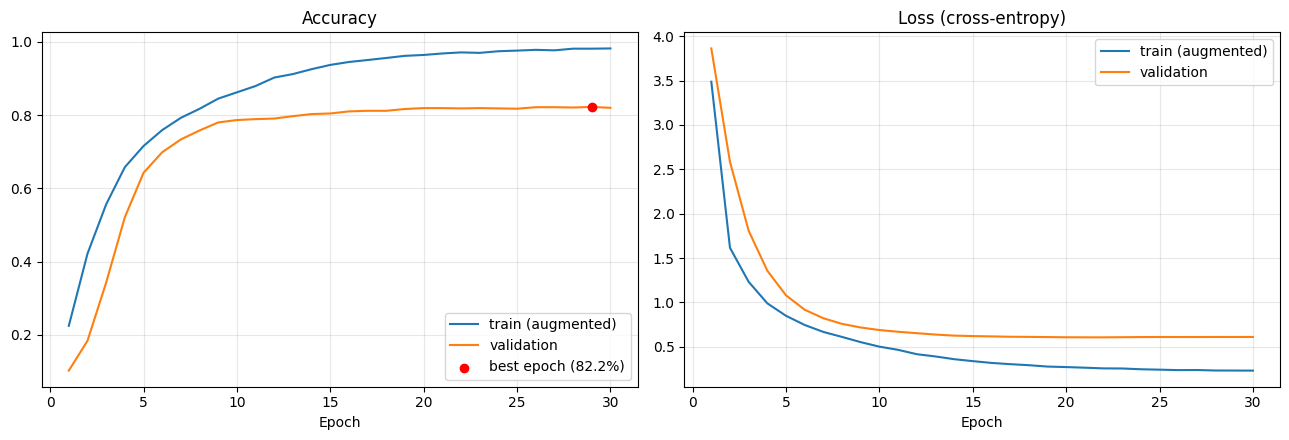

Train - validation accuracy gap at the best epoch: 15.9 points


In [12]:
h = pd.read_csv(HISTORY_PATH)
ep = h["epoch"].values
best = int(h["val_accuracy"].values.argmax())
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(ep, h["accuracy"], label="train (augmented)")
axes[0].plot(ep, h["val_accuracy"], label="validation")
axes[0].scatter(ep[best], h["val_accuracy"].values[best], color="red", zorder=3,
                label=f"best epoch ({h['val_accuracy'].values[best] * 100:.1f}%)")
axes[0].set_title("Accuracy")
axes[1].plot(ep, h["loss"], label="train (augmented)")
axes[1].plot(ep, h["val_loss"], label="validation")
axes[1].set_title("Loss (cross-entropy)")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR + "learning_curves.png", dpi=150)
plt.show()

gap = (h["accuracy"].values[best] - h["val_accuracy"].values[best]) * 100
print(f"Train - validation accuracy gap at the best epoch: {gap:.1f} points")

### Confusion matrix
Left: number of test images. Right: normalised per true class (each row sums to 100 %), which shows the recall of each emotion and which emotions are confused with each other.

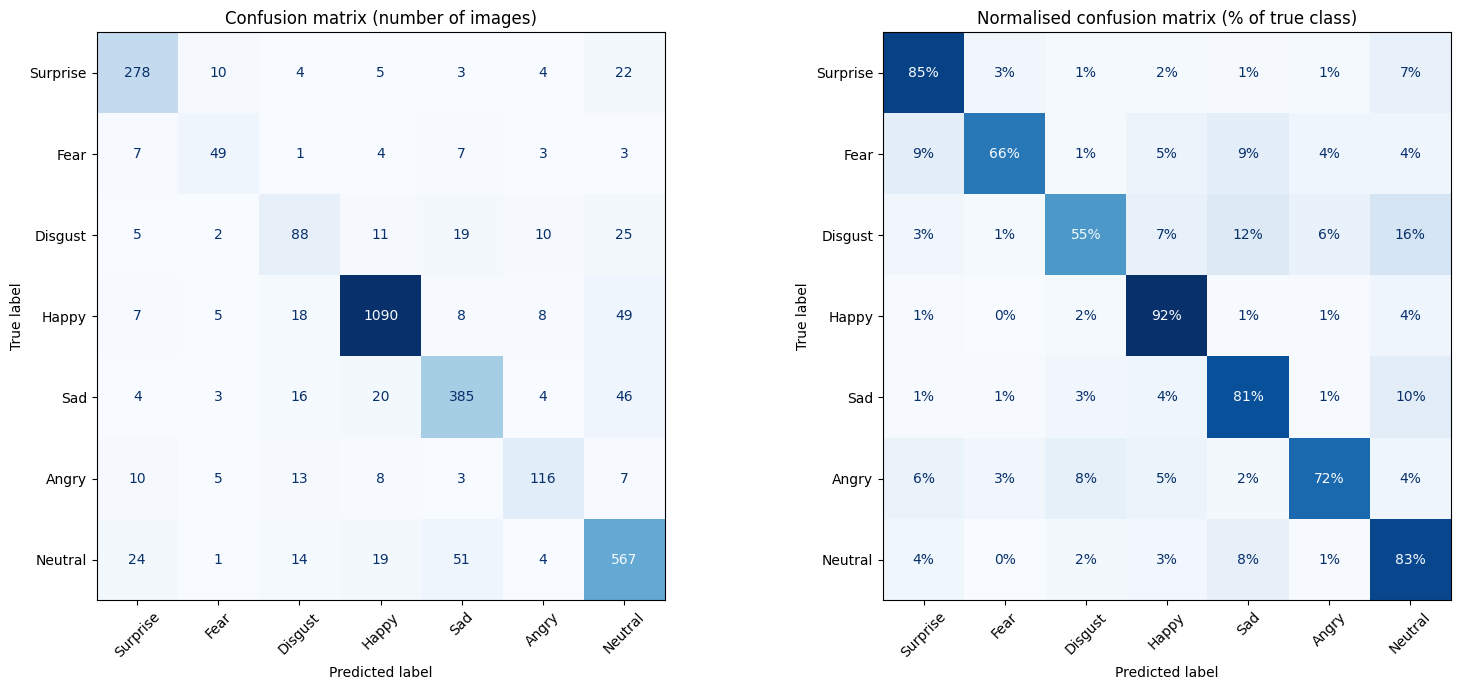

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=CLASS_NAMES).plot(
    ax=axes[0], cmap="Blues", xticks_rotation=45, colorbar=False)
axes[0].set_title("Confusion matrix (number of images)")

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, normalize="true"),
                       display_labels=CLASS_NAMES).plot(
    ax=axes[1], cmap="Blues", xticks_rotation=45, colorbar=False, values_format=".0%")
axes[1].set_title("Normalised confusion matrix (% of true class)")

plt.tight_layout()
plt.savefig(FIG_DIR + "confusion_matrix.png", dpi=150)
plt.show()

## 6. Error analysis

### Most confused emotions
The pairs below are the largest off-diagonal values of the normalised confusion matrix: the percentage of images of a true emotion that the model predicts as another one.

In [14]:
cm = confusion_matrix(y_test, y_pred)
cm_norm = cm / cm.sum(axis=1, keepdims=True)
pairs = [(cm_norm[i, j], CLASS_NAMES[i], CLASS_NAMES[j], cm[i, j])
         for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j]
for rate, true, pred, n in sorted(pairs, reverse=True)[:5]:
    print(f"{true:9} predicted as {pred:9}: {rate * 100:5.1f}%  ({n} images)")

Disgust   predicted as Neutral  :  15.6%  (25 images)
Disgust   predicted as Sad      :  11.9%  (19 images)
Sad       predicted as Neutral  :   9.6%  (46 images)
Fear      predicted as Surprise :   9.5%  (7 images)
Fear      predicted as Sad      :   9.5%  (7 images)


### Examples of predictions
Each image shows the true emotion, the predicted emotion and the model's confidence. Green = correct, red = incorrect. Images are randomly selected with a fixed seed.

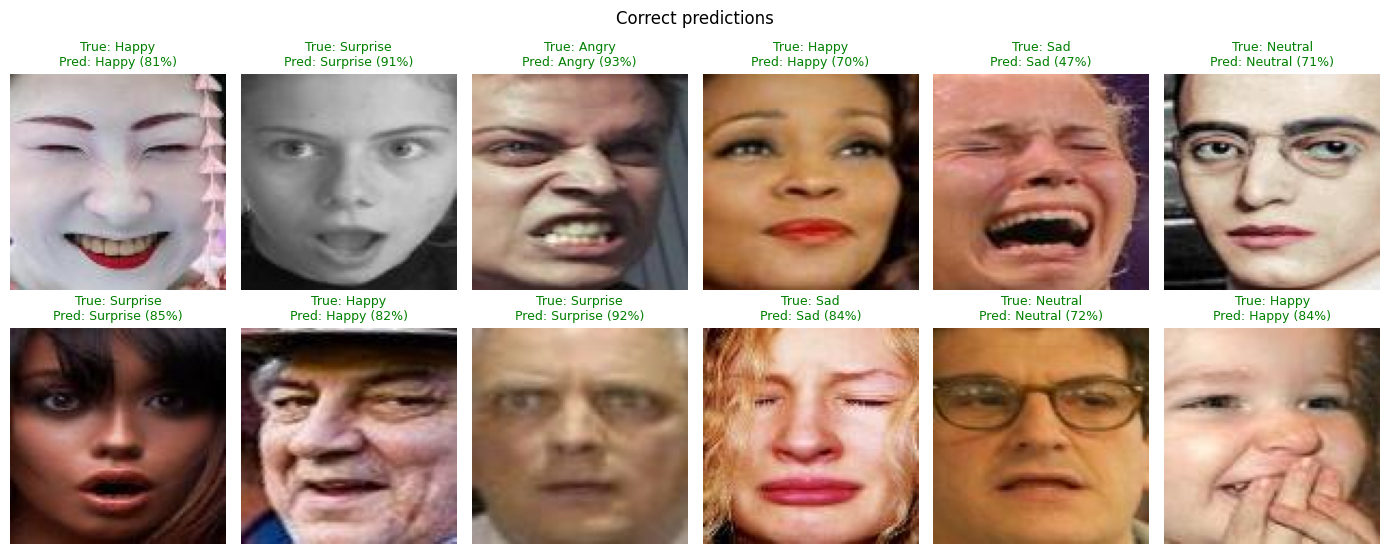

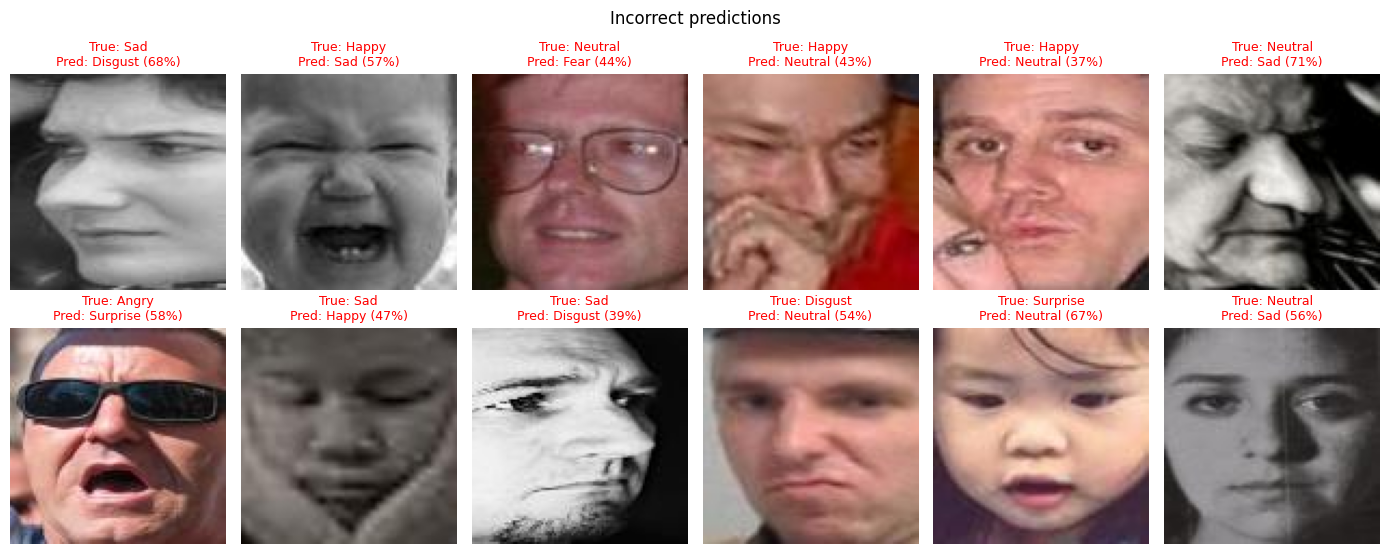

In [15]:
rng = np.random.default_rng(SEED)
correct_idx = np.where(y_pred == y_test)[0]
wrong_idx = np.where(y_pred != y_test)[0]

def show_examples(indices, title, filename):
    fig, axes = plt.subplots(2, 6, figsize=(14, 5.8))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, i in zip(axes.ravel(), indices):
        ax.imshow(read_rgb(test_paths[i]))
        ok = y_pred[i] == y_test[i]
        ax.set_title(f"True: {CLASS_NAMES[y_test[i]]}\n"
                     f"Pred: {CLASS_NAMES[y_pred[i]]} ({probs[i].max() * 100:.0f}%)",
                     fontsize=9, color="green" if ok else "red")
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(FIG_DIR + filename, dpi=150)
    plt.show()

show_examples(rng.choice(correct_idx, min(12, len(correct_idx)), replace=False),
              "Correct predictions", "examples_correct.png")
show_examples(rng.choice(wrong_idx, min(12, len(wrong_idx)), replace=False),
              "Incorrect predictions", "examples_errors.png")

### Predicting a new image
The model expects a **cropped and aligned face**, like the RAF-DB images. It does not include a face detector, so a photo with background must first be cropped around the face.

In [16]:
@torch.no_grad()
def predict_image(path, top_k=3):
    x = eval_transform(image=read_rgb(path))["image"].unsqueeze(0).to(device)
    p = torch.softmax(best_model(x).float(), 1) + torch.softmax(best_model(torch.flip(x, dims=[3])).float(), 1)
    p = (p / 2)[0].cpu().numpy()
    return [(CLASS_NAMES[i], float(p[i])) for i in p.argsort()[::-1][:top_k]]

for emotion, p in predict_image(test_paths[0]):
    print(f"{emotion:9}: {p * 100:.1f}%")

Surprise : 61.3%
Neutral  : 21.8%
Fear     : 7.3%


## 7. Final results
Summary of the experiment, compared with the first version, and saved to `results.json`.

In [17]:
results = {
    "test_accuracy": round(float(acc), 4),
    "test_accuracy_without_tta": round(float(acc_plain), 4),
    "macro_f1": round(float(f1_macro), 4),
    "weighted_f1": round(float(f1_weighted), 4),
    "best_val_accuracy": round(float(h["val_accuracy"].max()), 4),
    "best_epoch": int(ep[best]),
    "epochs_trained": int(len(h)),
    "train_val_gap_points": round(float(gap), 1),
    "first_version_test_accuracy": 0.8408,
    "per_class": classification_report(y_test, y_pred, target_names=CLASS_NAMES, output_dict=True),
}
with open(RUN_DIR + "results.json", "w") as f:
    json.dump(results, f, indent=2)

print("=" * 55)
print("                    FINAL RESULTS")
print("=" * 55)
print(f"Test accuracy (TTA)        : {acc * 100:.2f}%")
print(f"Test accuracy (no TTA)     : {acc_plain * 100:.2f}%")
print(f"Macro F1-score             : {f1_macro:.3f}")
print(f"Weighted F1-score          : {f1_weighted:.3f}")
print(f"Best epoch                 : {int(ep[best])} / {len(h)} trained")
print(f"Train - validation gap     : {gap:.1f} points")
print(f"First version              : 84.08%  ->  this version: {acc * 100:.2f}%  "
      f"({(acc - 0.8408) * 100:+.2f} points)")
print("=" * 55)
print("Saved to", RUN_DIR + "results.json")
print("Figures:", sorted(os.listdir(FIG_DIR)))

                    FINAL RESULTS
Test accuracy (TTA)        : 83.95%
Test accuracy (no TTA)     : 83.69%
Macro F1-score             : 0.765
Weighted F1-score          : 0.840
Best epoch                 : 29 / 30 trained
Train - validation gap     : 15.9 points
First version              : 84.08%  ->  this version: 83.95%  (-0.13 points)
Saved to /content/drive/MyDrive/Machine Learning/Emotion Recognition RAF DB/outputs/results.json
Figures: ['augmentation_examples.png', 'class_distribution.png', 'confusion_matrix.png', 'examples_correct.png', 'examples_errors.png', 'learning_curves.png']
